# Modeling: naive baseline vs. tuned ridge vs. tuned gradient boosting

Train and compare models that predict **SBP** and **DBP** from the 14 PPG features
built in `ppg_feature_extraction.ipynb`.

Pipeline, using the shared code in `../src/`:

1. Load `data/ppg_features.csv`.
2. Split into train/test **by whole recording** (`src/data_split.py`) — a recording's
   windows never end up split across train and test. **The test set is set aside here
   and never touched again until the final evaluation cell.**
3. Compute the **naive baseline**: always predict the training mean (`src/baseline.py`).
4. **Tune hyperparameters** using grouped K-fold cross-validation *within the train
   set only* (`src/cross_validation.py`):
   - Ridge: search `alpha` over `[0.001, 0.01, 0.1, 1, 10, 100, 1000]`.
   - Gradient boosting: search `learning_rate` x `max_leaf_nodes` x `min_samples_leaf`.
5. Refit the winning hyperparameters on the full train set and evaluate once on the
   held-out test recordings.
6. Explain predictions with **ridge coefficients** and **GBM permutation importance**
   (`src/importance.py`).

Run this notebook from `notebooks/`, after `preprocess.ipynb` and
`ppg_feature_extraction.ipynb` have produced `data/ppg_features.csv`.

**Note on runtime:** the gradient boosting grid search fits 45 hyperparameter
combinations x 5 folds x 2 targets = 450 models. A timing probe on this dataset found
individual fit time ranges from ~8s (`max_leaf_nodes=31`) to ~190s
(`max_leaf_nodes=1000`) depending on hyperparameters, since more leaf nodes means a
slower per-iteration split search. With `n_jobs=-1` (parallel across CPU cores) this
step can still take tens of minutes.

## Setup

Add the repo root to the path so we can import the shared `src/` modules.

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))

from src.data_split import grouped_train_test_split, split_summary
from src.baseline import compute_naive_baseline, evaluate_naive_baseline
from src.models import FEATURE_COLUMNS, fit_gbm, fit_ridge, evaluate_model
from src.cross_validation import ridge_alpha_search, gbm_param_search, RIDGE_ALPHA_GRID, GBM_PARAM_GRID
from src.importance import importance_report
from src.baseline import evaluate_predictions

results_dir = Path('../results')
graphs_dir = results_dir / 'graphs'
graphs_dir.mkdir(parents=True, exist_ok=True)

TARGET_COLS = ('sbp', 'dbp')
RANDOM_STATE = 42
N_SPLITS = 5

## 1. Load the feature table

One row per usable 5-second window: 14 PPG features, SBP/DBP labels, and source IDs
(`file`, `record_index`, `start_sample`) used to keep recordings intact during splitting.

In [2]:
df = pd.read_csv('../data/ppg_features.csv')
assert set(FEATURE_COLUMNS).issubset(df.columns)
assert set(TARGET_COLS).issubset(df.columns)
print(f'Loaded {len(df):,} rows, {df["file"].nunique()} source file(s), '
      f'{df[["file", "record_index"]].drop_duplicates().shape[0]:,} recordings.')
df.head()

Loaded 527,467 rows, 4 source file(s), 11,989 recordings.


,file,record_index,start_sample,inband_power_ratio,sbp,dbp,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,...,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats
0,Part_1.mat,0,0,0.988807,121.841618,67.185065,121.841155,6.651835,1.817359,0.139000,...,0.395105,0.172000,22.566971,0.603994,-1.015477,1.244404,2.259881,0.515651,-1.049128,8
1,Part_1.mat,0,625,0.986258,124.747842,68.967875,124.309392,3.771236,1.841432,0.141000,...,0.413552,0.173000,22.546255,0.603707,-0.828494,1.295174,2.123667,0.537671,-1.051481,8
2,Part_1.mat,0,1250,0.983730,125.846835,69.773803,123.966942,7.375636,1.856541,0.143111,...,0.418236,0.175111,22.574495,0.640492,-0.888280,1.567517,2.455796,0.498770,-1.004504,9
3,Part_1.mat,0,1875,0.989113,122.354481,67.111799,123.175182,6.999118,1.845592,0.138000,...,0.394474,0.170000,22.876972,0.652981,-1.261017,1.316331,2.577348,0.366763,-0.960664,8
4,Part_1.mat,0,2500,0.985247,125.578192,69.212096,124.309392,5.333333,1.879927,0.139000,...,0.405369,0.172000,23.149713,0.606510,-0.843065,1.166942,2.010007,0.537381,-1.074263,8


## 2. Split by recording

80/20 train/test split, keeping each recording's windows entirely in one split.
`stratify_col='file'` (the default) keeps Part_1-4 represented in similar proportions
in both splits.

**`test_df` is now set aside. It is not referenced again until the final evaluation
cell below.**

In [3]:
train_df, test_df = grouped_train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
split_summary(train_df, test_df)

,split,rows,recordings
0,train,420509,9589
1,test,106958,2400


## 3. Naive baseline

Always predict the training set's mean SBP/DBP, ignoring every feature. This is the
floor both real models need to beat.

In [4]:
baseline_values = compute_naive_baseline(train_df, TARGET_COLS)
baseline_results = evaluate_naive_baseline(baseline_values, test_df, TARGET_COLS)
print('Naive baseline (train-set mean):', baseline_values)
baseline_results.round(3)

Naive baseline (train-set mean): {'sbp': 128.8815851719202, 'dbp': 68.05336274194222}


,target,predicted_value,mae,rmse
0,sbp,128.882,18.545,22.809
1,dbp,68.053,9.151,11.985


## 4. Hyperparameter tuning (grouped K-fold CV, train set only)

For each target (SBP, DBP), search:

- **Ridge**: `alpha` in `[0.001, 0.01, 0.1, 1, 10, 100, 1000]`.
- **Gradient boosting**: `learning_rate` x `max_leaf_nodes` x `min_samples_leaf`
  (45 combinations).

Both searches use `GroupKFold` on `(file, record_index)` — a recording's windows
always land entirely in one fold, in both the outer train/test split and these inner
CV folds. Each hyperparameter combination is scored by its **average MAE across the
5 folds**; the test set is never part of this step.

In [5]:
ridge_cv_results = {}
ridge_best_alpha = {}

for target in TARGET_COLS:
    results, search = ridge_alpha_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    ridge_cv_results[target] = results
    ridge_best_alpha[target] = search.best_params_['ridge__alpha']
    print(f'--- Ridge CV for {target.upper()} ---')
    display(results)
    print(f'Best alpha: {ridge_best_alpha[target]}\n')

--- Ridge CV for SBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,17.565120,0.384452
1,{'ridge__alpha': 0.01},2,17.565120,0.384452
2,{'ridge__alpha': 0.1},3,17.565121,0.384451
3,{'ridge__alpha': 1},4,17.565125,0.384449
4,{'ridge__alpha': 10},5,17.565166,0.384422
5,{'ridge__alpha': 100},6,17.565614,0.384146
6,{'ridge__alpha': 1000},7,17.572344,0.381146


Best alpha: 0.001



--- Ridge CV for DBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,8.707269,0.181256
1,{'ridge__alpha': 0.01},2,8.707269,0.181256
2,{'ridge__alpha': 0.1},3,8.707269,0.181256
3,{'ridge__alpha': 1},4,8.707275,0.181256
4,{'ridge__alpha': 10},5,8.707331,0.181259
5,{'ridge__alpha': 100},6,8.707902,0.181287
6,{'ridge__alpha': 1000},7,8.714091,0.181356


Best alpha: 0.001



In [6]:
gbm_cv_results = {}
gbm_best_params = {}

for target in TARGET_COLS:
    results, search = gbm_param_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    gbm_cv_results[target] = results
    gbm_best_params[target] = search.best_params_
    print(f'--- Gradient boosting CV for {target.upper()} (top 5 of {len(results)} combos) ---')
    display(results.head())
    print(f'Best params: {gbm_best_params[target]}\n')

--- Gradient boosting CV for SBP (top 5 of 45 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",1,14.538748,0.419208
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",2,14.585029,0.414823
2,"{'learning_rate': 0.1, 'max_leaf_nodes': 1000,...",3,14.607488,0.413327
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 1000,...",4,14.673862,0.413968
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",5,14.685745,0.413910


Best params: {'learning_rate': 0.05, 'max_leaf_nodes': 1000, 'min_samples_leaf': 20}



--- Gradient boosting CV for DBP (top 5 of 45 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",1,7.641832,0.196065
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",2,7.664736,0.180559
2,"{'learning_rate': 0.1, 'max_leaf_nodes': 1000,...",3,7.682629,0.175785
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 316, ...",4,7.714273,0.196656
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",5,7.720402,0.181838


Best params: {'learning_rate': 0.05, 'max_leaf_nodes': 1000, 'min_samples_leaf': 20}



## 5. Refit with the winning hyperparameters, evaluate once on the test set

Refit ridge and gradient boosting on the **full** train set using each target's best
hyperparameters from the CV search above, then evaluate on the held-out test
recordings — the first and only time `test_df` is used.

In [7]:
rows = []
fitted_models = {}

for target in TARGET_COLS:
    # Naive baseline, scored on test (same as section 3, included here for one table).
    import numpy as np
    constant_pred = np.full(len(test_df), baseline_values[target])
    rows.append({'target': target, 'model': 'naive_baseline',
                 **evaluate_predictions(test_df[target], constant_pred)})

    ridge_model = fit_ridge(train_df, target, FEATURE_COLUMNS, alpha=ridge_best_alpha[target])
    fitted_models[(target, 'ridge')] = ridge_model
    rows.append({'target': target, 'model': 'ridge (tuned)',
                 **evaluate_model(ridge_model, test_df, target, FEATURE_COLUMNS)})

    gbm_model = fit_gbm(train_df, target, FEATURE_COLUMNS, random_state=RANDOM_STATE, **gbm_best_params[target])
    fitted_models[(target, 'gbm')] = gbm_model
    rows.append({'target': target, 'model': 'gbm (tuned)',
                 **evaluate_model(gbm_model, test_df, target, FEATURE_COLUMNS)})

results = pd.DataFrame(rows)[['target', 'model', 'mae', 'rmse']]
results.round(3)

,target,model,mae,rmse
0,sbp,naive_baseline,18.545,22.809
1,sbp,ridge (tuned),17.748,22.097
2,sbp,gbm (tuned),14.661,19.258
3,dbp,naive_baseline,9.151,11.985
4,dbp,ridge (tuned),8.826,11.724
5,dbp,gbm (tuned),7.555,10.572


## 6. Compare the three models

For each target, how much do tuned ridge and tuned gradient boosting improve on the
naive baseline?

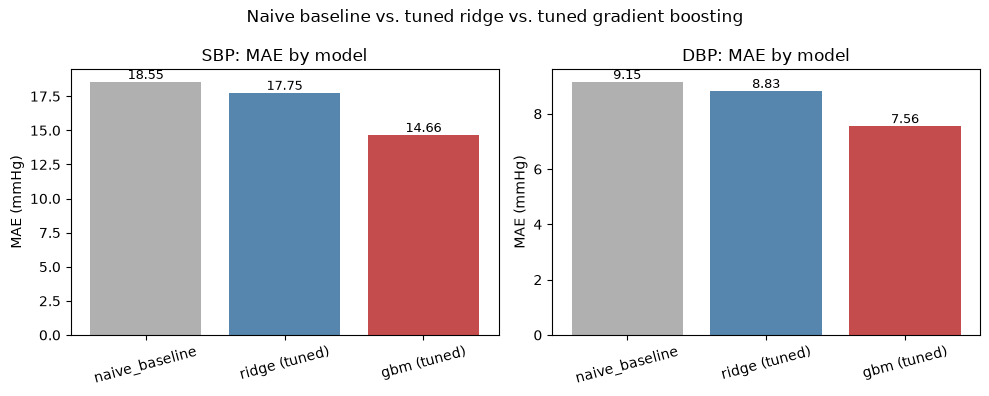

In [8]:
import matplotlib.pyplot as plt

model_order = ['naive_baseline', 'ridge (tuned)', 'gbm (tuned)']
colors = {'naive_baseline': '#b0b0b0', 'ridge (tuned)': '#5686ad', 'gbm (tuned)': '#c44c4c'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, target in zip(axes, TARGET_COLS):
    subset = results[results['target'] == target].set_index('model').loc[model_order]
    ax.bar(model_order, subset['mae'], color=[colors[m] for m in model_order])
    ax.set_title(f'{target.upper()}: MAE by model')
    ax.set_ylabel('MAE (mmHg)')
    ax.tick_params(axis='x', rotation=15)
    for i, value in enumerate(subset['mae']):
        ax.text(i, value, f'{value:.2f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('Naive baseline vs. tuned ridge vs. tuned gradient boosting')
fig.tight_layout()
fig.savefig(graphs_dir / 'model_comparison.png', dpi=150)
plt.show()
plt.close(fig)

## 7. Feature importance

- **Ridge**: standardized coefficients — size is directly comparable across all 14
  features; sign shows direction.
- **Gradient boosting**: permutation importance on the *test* split, not the model's
  built-in `feature_importances_` (which can be misleading with correlated features
  like `rise_time_s`/`fall_time_s`/`rise_fall_ratio`).

In [9]:
importance = importance_report(fitted_models, test_df, target_cols=TARGET_COLS)
for target in TARGET_COLS:
    print(f'--- {target.upper()} ---')
    display(importance[importance['target'] == target].drop(columns='target').round(3))

--- SBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
0,pulse_height,-17.943,17.943,2.367,0.014
1,max_upslope,11.385,11.385,3.512,0.024
2,ppg_std,8.334,8.334,1.785,0.017
3,heart_rate_bpm,-4.193,4.193,1.125,0.010
4,rise_fall_ratio,-3.972,3.972,1.123,0.009
5,ppg_kurtosis,-3.760,3.760,0.729,0.012
6,ppg_min,-3.183,3.183,0.214,0.005
7,fall_time_s,-2.270,2.270,0.889,0.006
8,ppg_skewness,1.878,1.878,1.235,0.010
9,ppg_max,-1.853,1.853,0.213,0.005


--- DBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
14,pulse_height,-8.915,8.915,1.914,0.015
15,max_upslope,6.871,6.871,2.357,0.017
16,ppg_std,2.012,2.012,0.433,0.005
17,pulse_width_s,1.808,1.808,0.884,0.008
18,rise_time_s,1.646,1.646,0.703,0.006
19,heart_rate_bpm,1.283,1.283,0.862,0.005
20,ppg_min,-1.033,1.033,0.109,0.002
21,ppg_kurtosis,-0.984,0.984,0.528,0.004
22,rise_fall_ratio,-0.895,0.895,0.708,0.005
23,fall_time_s,0.571,0.571,0.393,0.004


## 8. Visualize feature importance

Ridge coefficients and GBM permutation importance, side by side, per target.

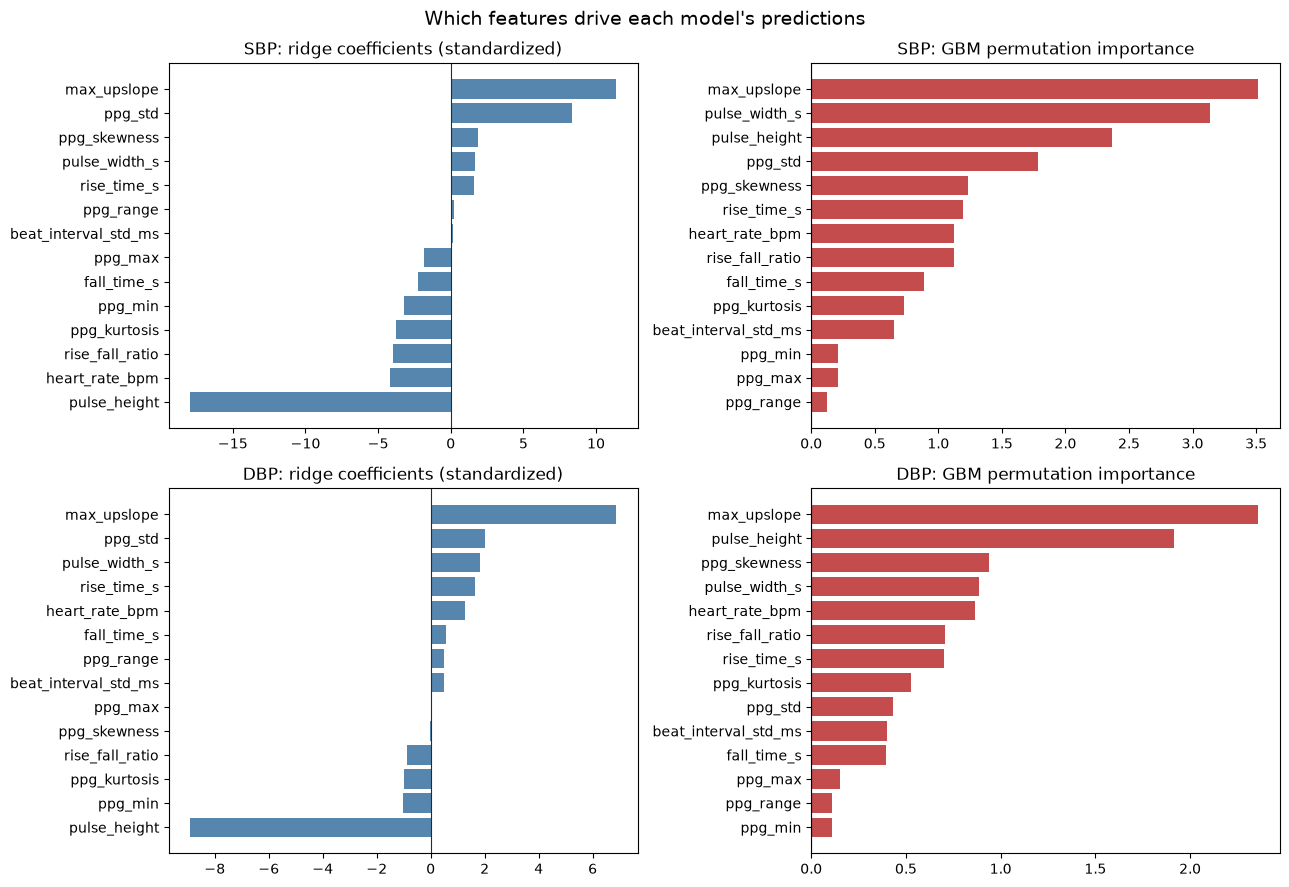

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, target in enumerate(TARGET_COLS):
    subset = importance[importance['target'] == target].set_index('feature')

    ax = axes[row, 0]
    ordered = subset.sort_values('coefficient')
    ax.barh(ordered.index, ordered['coefficient'], color='#5686ad')
    ax.set_title(f'{target.upper()}: ridge coefficients (standardized)')
    ax.axvline(0, color='#183047', linewidth=0.8)

    ax = axes[row, 1]
    ordered = subset.sort_values('importance_mean')
    ax.barh(ordered.index, ordered['importance_mean'], color='#c44c4c')
    ax.set_title(f'{target.upper()}: GBM permutation importance')
    ax.axvline(0, color='#183047', linewidth=0.8)

fig.suptitle('Which features drive each model\'s predictions', fontsize=14)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_importance.png', dpi=150)
plt.show()
plt.close(fig)

## Notes

- All metrics are computed on recordings the models never trained on, and the
  hyperparameter search never saw the test set either — see `src/data_split.py` and
  `src/cross_validation.py` for how that's enforced.
- Ridge and GBM being close to the naive baseline (rather than far below it) would
  match the weak single-feature correlations already seen in
  `ppg_feature_extraction.ipynb` (best |r| &asymp; 0.16 for SBP, &asymp; 0.09 for DBP).
  That's an expected, honest result for this feature set — not necessarily a bug.
- The gradient boosting CV search showed per-fit time growing sharply with
  `max_leaf_nodes` (roughly 8s at 31 leaves vs. ~190s at 1000 leaves on this dataset)
  because larger trees mean a slower split search per boosting iteration, not because
  of more boosting rounds.
- Next steps if these results look weak: try more/different PPG features, widen the
  CV search, or try a longer window length.